# Model evaluation

Comparison of Gemma 3 baselines, SFT adapters, and DPO adapters on the same 315 validation turns.
The main comparison uses instruction-tuned (IT) starting checkpoints at 1B and 12B, with 27B IT as a baseline. The 12B pretrained (PT) branch is reported separately.

Reference-based metrics measure similarity to the recorded nurse response. The judge rates safety and role adherence, clinical usefulness for handoff, contextual relevance, and clarity and conciseness on a three-point scale.

In [1]:
from IPython.display import display

import story_utils as S

items = S.load_items()

MAIN_MODELS = S.SIZE_GROUPS["1b"] + S.SIZE_GROUPS["12b_it"] + ["base/27b"]
PT_MODELS = ["sft/12b-pt", "dpo/12b-pt"]
METRICS = ["rouge1", "rouge2", "rougeL", "bleu", "bertscore_f1",
           "e5_cosine", "modernbertic_cosine"]

## Reference-based metrics

Scores are averaged over the 315 validation turns. Higher values indicate greater similarity to the reference; they do not directly measure whether a response follows the task or asks a useful question.

In [2]:
S.metrics_table(items, models=MAIN_MODELS, metrics=METRICS)

,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,BERTScore F1,E5 cosine,ModernBERTić cosine
1B IT baseline,0.1505,0.0376,0.1343,0.0125,0.6824,0.8351,0.9239
1B IT → SFT,0.2867,0.1432,0.2755,0.0762,0.7379,0.8678,0.9419
1B IT → SFT → DPO,0.2652,0.1160,0.2522,0.0714,0.7349,0.8633,0.9407
12B IT baseline,0.1528,0.0523,0.1388,0.0091,0.6701,0.8344,0.9326
12B IT → SFT,0.3057,0.1511,0.2929,0.0865,0.7490,0.8741,0.9465
12B IT → SFT → DPO,0.2858,0.1279,0.2748,0.0779,0.7407,0.8703,0.9445
27B IT baseline,0.1605,0.0541,0.1453,0.0136,0.6780,0.8389,0.9325


## Judge scores

Ratings are encoded as 1 (poor), 2 (adequate), and 3 (good). Each column averages one rubric across turns; the final column averages the four rubric means. The recorded reference response is included for comparison.

In [3]:
S.rubric_mean_table(items, models=MAIN_MODELS)

,Safety and role adherence,Clinical usefulness for handoff,Contextual relevance,Clarity and conciseness,Mean
1B IT baseline,1.399,1.286,1.382,1.179,1.311
1B IT → SFT,2.156,1.864,1.983,1.761,1.941
1B IT → SFT → DPO,2.352,1.947,2.103,2.093,2.124
12B IT baseline,2.688,2.571,2.472,2.136,2.467
12B IT → SFT,2.701,2.429,2.488,2.678,2.574
12B IT → SFT → DPO,2.837,2.681,2.721,2.824,2.766
27B IT baseline,2.787,2.724,2.681,2.528,2.680
Reference response,2.761,2.615,2.605,2.688,2.667


## Rating distributions

Each bar shows the share of ratings at each level for one model and rubric. These distributions show changes that can be obscured by a mean score.

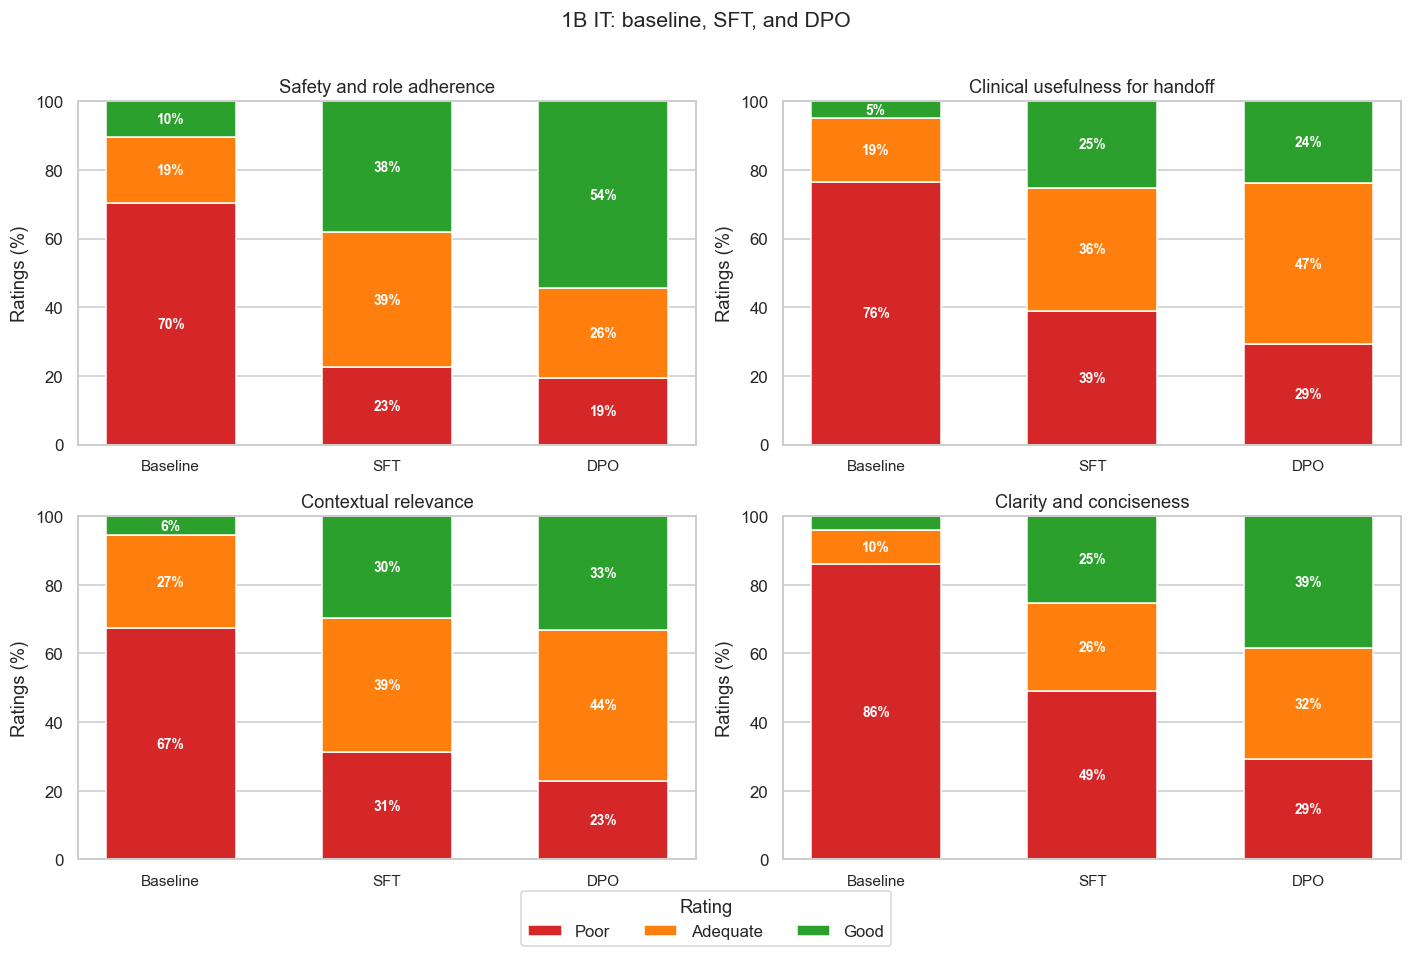

In [4]:
S.plot_rubric_stacked_pct(
    items, S.SIZE_GROUPS["1b"], name="05_1b_rubric_stacked",
    title="1B IT: baseline, SFT, and DPO",
)

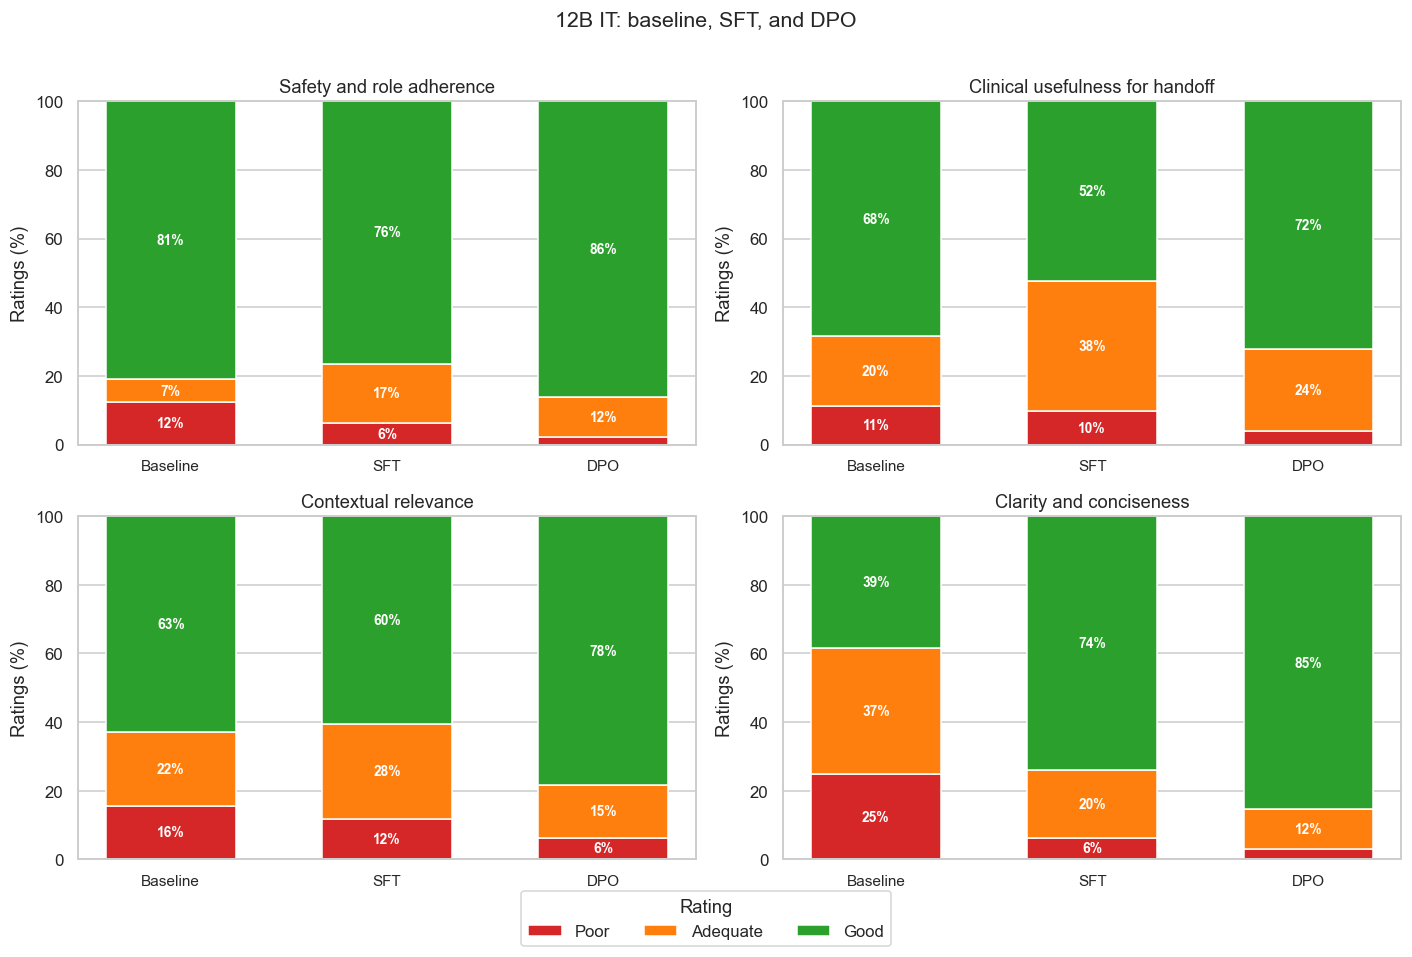

In [5]:
S.plot_rubric_stacked_pct(
    items, S.SIZE_GROUPS["12b_it"], name="12b_it_rubric_stacked",
    title="12B IT: baseline, SFT, and DPO",
)

## 12B pretrained branch

These adapters start from the 12B PT checkpoint. The baseline below uses the 12B IT checkpoint, so its difference from the PT adapters includes a change of starting checkpoint as well as task-specific training.

In [6]:
display(S.metrics_table(items, models=PT_MODELS, metrics=METRICS))
display(S.rubric_mean_table(items, models=PT_MODELS))

,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,BERTScore F1,E5 cosine,ModernBERTić cosine
12B PT → SFT,0.3051,0.1542,0.2955,0.0936,0.7517,0.8751,0.9462
12B PT → SFT → DPO,0.2898,0.1243,0.2800,0.0761,0.7495,0.8739,0.9461


,Safety and role adherence,Clinical usefulness for handoff,Contextual relevance,Clarity and conciseness,Mean
12B PT → SFT,2.688,2.482,2.548,2.751,2.617
12B PT → SFT → DPO,2.844,2.618,2.708,2.867,2.759
Reference response,2.761,2.615,2.605,2.688,2.667


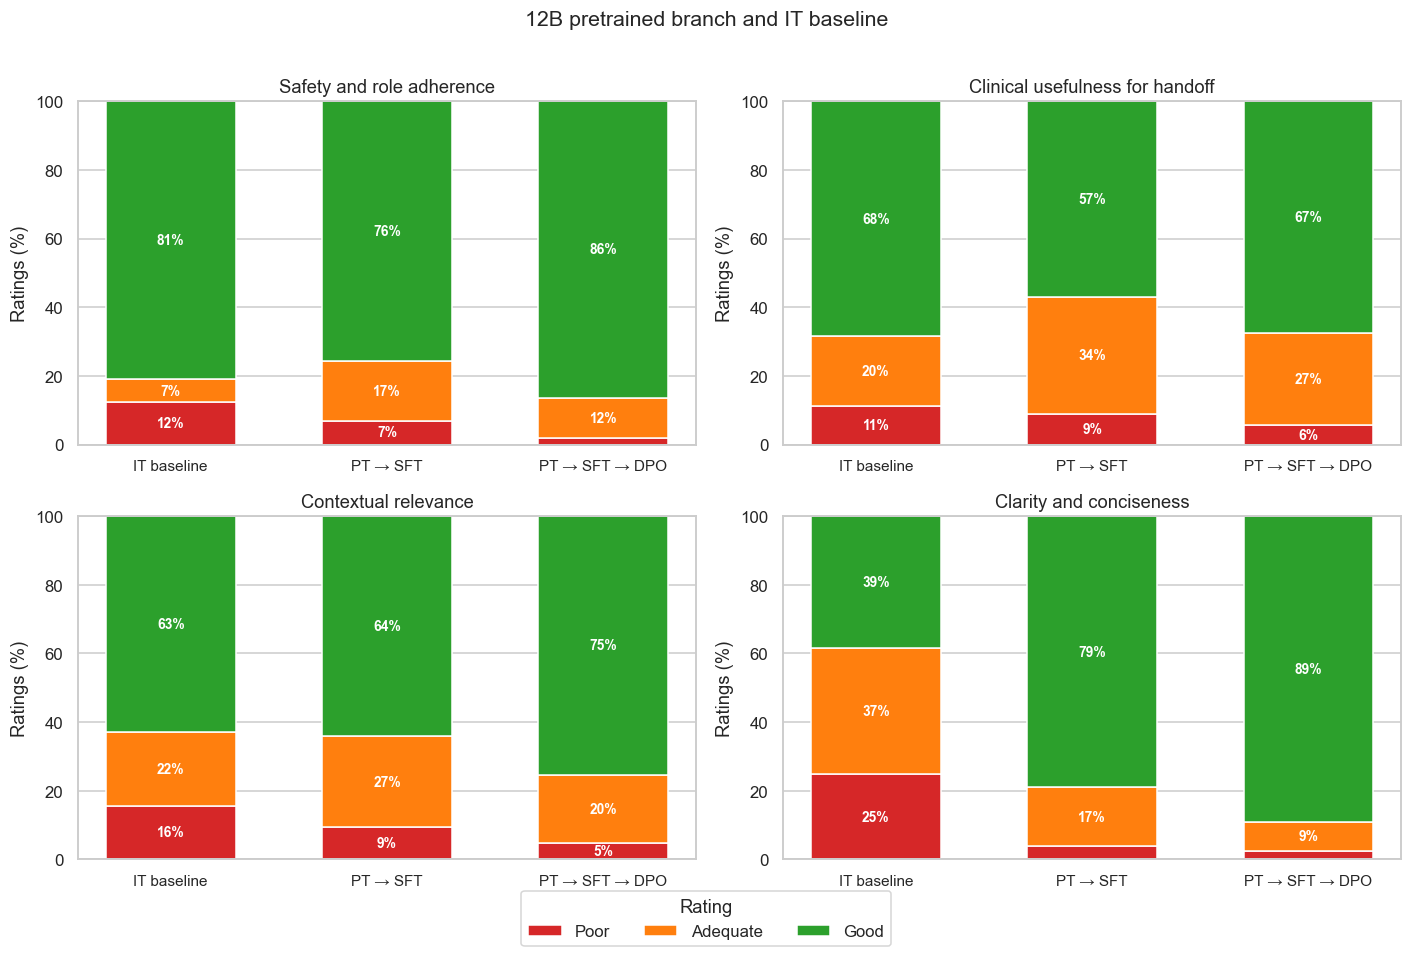

In [7]:
S.plot_rubric_stacked_pct(
    items, S.SIZE_GROUPS["12b"], name="06_12b_rubric_stacked",
    title="12B pretrained branch and IT baseline",
    labels={"base/12b": "IT baseline", "sft/12b-pt": "PT → SFT",
            "dpo/12b-pt": "PT → SFT → DPO"},
)

## Interpretation

In the main IT comparison, SFT improves both reference-based metrics and judge scores. DPO raises the overall judge score further, with a small decrease in reference-based metrics relative to SFT. The 12B IT DPO model scores highest overall, while the 27B IT baseline retains the highest clinical-usefulness score.

These are validation results: the same split guides SFT checkpoint selection. The judge also supplies the training preferences used by DPO, so higher judge scores need independent human evaluation before broader conclusions can be drawn.

The DPO pairs come from four SFT candidates per training example. The judge compares each pair in both response orders to reduce position bias. Copeland ranking selects the top and bottom candidates; the pair is kept only if the top candidate wins their direct comparison in both orders. Empty chosen responses and identical pairs are excluded.

See the separate response analyses for [1B](overview_1b.ipynb), [12B PT](overview_12b.ipynb), and [cross-model comparison](overview_1b_12b_27b.ipynb), or the [metric correlations](metric_correlations.ipynb).